# IDRAK | NLP Banking Intent Classification System

**Dataset:** Banking77 (PolyAI) — 13,083 Customer Service Inquiries across 77 Intent Categories

This notebook consolidates the complete end-to-end data science pipeline across **Day 1**, **Day 2**, and **Day 3** matching Kitt requirements.

---
# Day 1: Understand the Task and Text (Data Understanding & EDA)

### Problem Statement:
> *"We want to classify single-turn customer service banking messages into 77 fine-grained intent categories using natural language text to automate query routing."*

### Evaluation Metrics:
- **Macro F1-Score** & **Accuracy** (penalizes misclassifications across subtle classes equally).

### 1.1 Load Dataset
Loading official PolyAI train and test sets from GitHub.

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

train_url = "https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/master/banking_data/train.csv"
test_url = "https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/master/banking_data/test.csv"

df_train = pd.read_csv(train_url)
df_test = pd.read_csv(test_url)

print(f"Train samples: {len(df_train)}")
print(f"Test samples: {len(df_test)}")
print(f"Number of classes: {df_train['category'].nunique()}")
df_train.head()

Train samples: 10003
Test samples: 3080
Number of classes: 77


,text,category
0,I am still waiting on my card?,card_arrival
1,What can I do if my card still hasn't arrived ...,card_arrival
2,I have been waiting over a week. Is the card s...,card_arrival
3,Can I track my card while it is in the process...,card_arrival
4,"How do I know if I will get my card, or if it ...",card_arrival


### 1.2 Data Quality Checks (Track C)
Verifying zero missing values, duplicates, and zero data leakage between train and test.

In [14]:
{
    "train_missing": df_train.isnull().sum().to_dict(),
    "test_missing": df_test.isnull().sum().to_dict(),
    "train_duplicates": int(df_train.duplicated(subset=["text"]).sum()),
    "test_train_overlap": len(set(df_train["text"]).intersection(set(df_test["text"])))
}

{'train_missing': {'text': 0, 'category': 0},
 'test_missing': {'text': 0, 'category': 0},
 'train_duplicates': 0,
 'test_train_overlap': 0}

### 1.3 Class Balance (Track A)
Checking the distribution of examples across all 77 intent categories.

In [15]:
class_counts = df_train["category"].value_counts()

pd.DataFrame({
    "Metric": ["Total Classes", "Max per Class", "Min per Class", "Mean per Class"],
    "Value": [len(class_counts), class_counts.max(), class_counts.min(), round(class_counts.mean(), 1)]
})

,Metric,Value
0,Total Classes,77.0
1,Max per Class,187.0
2,Min per Class,35.0
3,Mean per Class,129.9


### 1.4 Text Length Exploration (Track B)
Calculating message lengths and plotting the distribution.

In [16]:
df_train["word_count"] = df_train["text"].apply(lambda x: len(x.split()))
df_train["char_count"] = df_train["text"].apply(len)

df_train[["word_count", "char_count"]].describe().round(1)

,word_count,char_count
count,10003.0,10003.0
mean,11.9,59.5
std,7.9,40.9
min,2.0,13.0
25%,7.0,36.0
50%,10.0,47.0
75%,13.0,64.0
max,79.0,433.0


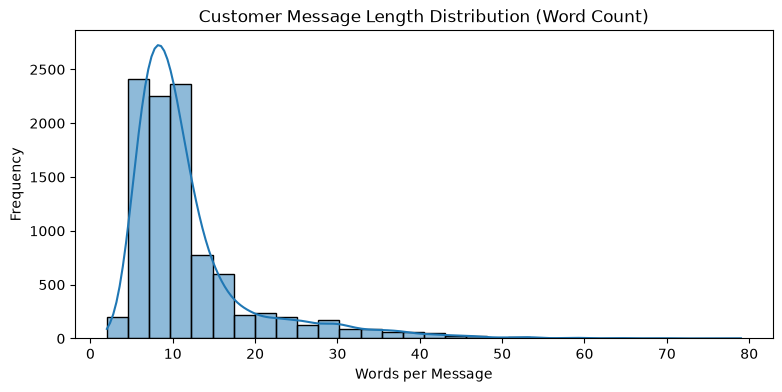

In [17]:
plt.figure(figsize=(9, 4))
sns.histplot(df_train["word_count"], bins=30, kde=True, color="#1f77b4")
plt.title("Customer Message Length Distribution (Word Count)", fontsize=12)
plt.xlabel("Words per Message")
plt.ylabel("Frequency")
plt.savefig("word_length_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

### 1.5 Domain Understanding & Semantic Overlap (Track D)
Inspecting example pairs with subtle lexical differences (e.g. card arrival vs delivery estimate).

In [18]:
pd.concat([
    df_train[df_train["category"] == "card_arrival"][["text", "category"]].head(3),
    df_train[df_train["category"] == "card_delivery_estimate"][["text", "category"]].head(3)
]).reset_index(drop=True)

,text,category
0,I am still waiting on my card?,card_arrival
1,What can I do if my card still hasn't arrived ...,card_arrival
2,I have been waiting over a week. Is the card s...,card_arrival
3,Can it specifically be delivered on a certain ...,card_delivery_estimate
4,I need to get my card quickly,card_delivery_estimate
5,When can I expect my card? I live in the US.,card_delivery_estimate


### 1.6 Export Shared Clean Split
Saving standardized clean data files for reproducible team experiments.

In [19]:
df_train.to_csv("train_clean.csv", index=False)
df_test.to_csv("test_clean.csv", index=False)

{"status": "Data exported successfully", "train_rows": len(df_train), "test_rows": len(df_test)}

{'status': 'Data exported successfully',
 'train_rows': 10003,
 'test_rows': 3080}

---
# Day 2: Build a Text Baseline (Baseline Modeling & Cross-Validation)

**Goal:** Establish the Dummy Baseline floor, build a leak-free TF-IDF pipeline, and validate with 5-Fold Cross-Validation.

### 2.1 Load Clean Data & Setup Split

In [20]:
import joblib
from sklearn.metrics import accuracy_score, f1_score

train_df = pd.read_csv("train_clean.csv")
test_df = pd.read_csv("test_clean.csv")

X_train, y_train = train_df["text"], train_df["category"]
X_test, y_test = test_df["text"], test_df["category"]

print(f"Train size: {len(X_train)} | Test size: {len(X_test)}")

Train size: 10003 | Test size: 3080


### 2.2 Dummy Baseline (Track B)
Predicting the most frequent class to establish the minimum baseline floor.

In [21]:
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)

pd.DataFrame({
    "Baseline": ["Dummy Classifier (Most Frequent)"],
    "Accuracy (%)": [round(accuracy_score(y_test, dummy_pred) * 100, 2)],
    "Macro F1 (%)": [round(f1_score(y_test, dummy_pred, average="macro", zero_division=0) * 100, 2)]
})

,Baseline,Accuracy (%),Macro F1 (%)
0,Dummy Classifier (Most Frequent),1.3,0.03


### 2.3 Integrated Text Preprocessing & Baseline Model (Tracks A & B)
Reusable Scikit-Learn Pipeline fitted strictly on training data (Zero Data Leakage).

In [22]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

baseline_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), max_features=10000, sublinear_tf=True)),
    ("classifier", LogisticRegression(C=5.0, max_iter=1000, class_weight="balanced", random_state=42))
])

baseline_pipeline.fit(X_train, y_train)
y_pred = baseline_pipeline.predict(X_test)

### 2.4 5-Fold Stratified Cross-Validation
Confirming model stability and checking for overfitting on training data.

In [23]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(baseline_pipeline, X_train, y_train, cv=5, scoring="accuracy")

pd.DataFrame({
    "Validation Metric": ["CV Mean Accuracy", "CV Std Deviation", "Test Accuracy"],
    "Score (%)": [round(cv_scores.mean() * 100, 2), round(cv_scores.std() * 100, 2), round(accuracy_score(y_test, y_pred) * 100, 2)]
})

,Validation Metric,Score (%)
0,CV Mean Accuracy,87.58
1,CV Std Deviation,0.61
2,Test Accuracy,89.42


### 2.5 Model Comparison: Logistic Regression vs. Linear SVM
Benchmarking two meaningful text classification architectures.

In [24]:
from sklearn.svm import LinearSVC

svm_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), max_features=10000, sublinear_tf=True)),
    ("classifier", LinearSVC(C=1.0, random_state=42))
])
svm_pipeline.fit(X_train, y_train)
svm_pred = svm_pipeline.predict(X_test)

comparison_df = pd.DataFrame({
    "Model": ["Logistic Regression (Baseline)", "Linear SVM"],
    "Test Accuracy (%)": [
        round(accuracy_score(y_test, y_pred) * 100, 2),
        round(accuracy_score(y_test, svm_pred) * 100, 2)
    ],
    "Macro F1 (%)": [
        round(f1_score(y_test, y_pred, average="macro") * 100, 2),
        round(f1_score(y_test, svm_pred, average="macro") * 100, 2)
    ]
})
comparison_df

,Model,Test Accuracy (%),Macro F1 (%)
0,Logistic Regression (Baseline),89.42,89.46
1,Linear SVM,89.06,89.06


### 2.6 Export Model Artifacts
Serializing the trained pipeline and class labels for evaluation and dashboard.

In [25]:
joblib.dump(baseline_pipeline, "banking_pipeline.joblib")
joblib.dump(sorted(y_train.unique()), "categories.joblib")

{"status": "Model artifacts saved successfully"}

{'status': 'Model artifacts saved successfully'}

---
# Day 3: Improve the Model, Error Analysis & Predictions

**Goal:** Deep performance diagnostics, Top-3 accuracy evaluation, error pattern analysis, and interactive prediction.

### 3.1 Load Artifacts & Compute Top-1 vs. Top-3 Accuracy
Evaluating customer service assistance where the Top-3 intent suggestions aid routing.

In [26]:
from sklearn.metrics import precision_score, recall_score

model = joblib.load("banking_pipeline.joblib")
categories = joblib.load("categories.joblib")

probs = model.predict_proba(X_test)
top3_indices = np.argsort(probs, axis=1)[:, -3:]
classes = model.classes_
top3_predictions = [[classes[idx] for idx in row] for row in top3_indices]
top3_accuracy = np.mean([actual in top3 for actual, top3 in zip(y_test, top3_predictions)])

pd.DataFrame({
    "Evaluation Metric": ["Top-1 Accuracy", "Top-3 Accuracy", "Macro Precision", "Macro Recall", "Macro F1-Score"],
    "Score (%)": [
        round(accuracy_score(y_test, y_pred) * 100, 2),
        round(top3_accuracy * 100, 2),
        round(precision_score(y_test, y_pred, average="macro") * 100, 2),
        round(recall_score(y_test, y_pred, average="macro") * 100, 2),
        round(f1_score(y_test, y_pred, average="macro") * 100, 2)
    ]
})

,Evaluation Metric,Score (%)
0,Top-1 Accuracy,89.42
1,Top-3 Accuracy,97.08
2,Macro Precision,89.87
3,Macro Recall,89.42
4,Macro F1-Score,89.46


### 3.2 Error Analysis: Top Confused Intent Pairs (Track D)
Identifying specific intent pairs with the highest confusion rate.

In [27]:
errors_df = test_df[y_test != y_pred].copy()
errors_df["predicted"] = y_pred[y_test != y_pred]

confused_pairs = (
    errors_df.groupby(["category", "predicted"])
    .size()
    .reset_index(name="Error Count")
    .sort_values(by="Error Count", ascending=False)
    .head(10)
    .reset_index(drop=True)
)
confused_pairs.columns = ["Actual Intent", "Predicted Intent", "Error Count"]
confused_pairs

,Actual Intent,Predicted Intent,Error Count
0,why_verify_identity,verify_my_identity,6
1,pin_blocked,get_physical_card,5
2,card_acceptance,card_not_working,5
3,unable_to_verify_identity,verify_my_identity,5
4,top_up_reverted,top_up_failed,5
5,fiat_currency_support,exchange_via_app,4
6,wrong_exchange_rate_for_cash_withdrawal,card_payment_wrong_exchange_rate,4
7,transfer_not_received_by_recipient,balance_not_updated_after_bank_transfer,4
8,pending_top_up,top_up_failed,4
9,balance_not_updated_after_bank_transfer,transfer_not_received_by_recipient,4


### 3.3 Error Analysis: Real Misclassified Customer Queries
Inspecting privacy-safe customer queries that led to classification errors.

In [28]:
sample_errors = errors_df[["text", "category", "predicted"]].head(6)
sample_errors.columns = ["Customer Query", "Actual Intent", "Predicted Intent"]
sample_errors.reset_index(drop=True)

,Customer Query,Actual Intent,Predicted Intent
0,How do I locate my card?,card_arrival,card_not_working
1,I ordered a card but it has not arrived. Help ...,card_arrival,transfer_not_received_by_recipient
2,When will I get my card?,card_arrival,card_delivery_estimate
3,How long does a card delivery take?,card_arrival,card_delivery_estimate
4,How do I know when my card will arrive?,card_arrival,card_delivery_estimate
5,I'm starting to think my card is lost because ...,card_arrival,lost_or_stolen_card


### 3.4 Error Visualization for Presentation Slides
Plotting and exporting the Top Confused Intents chart.

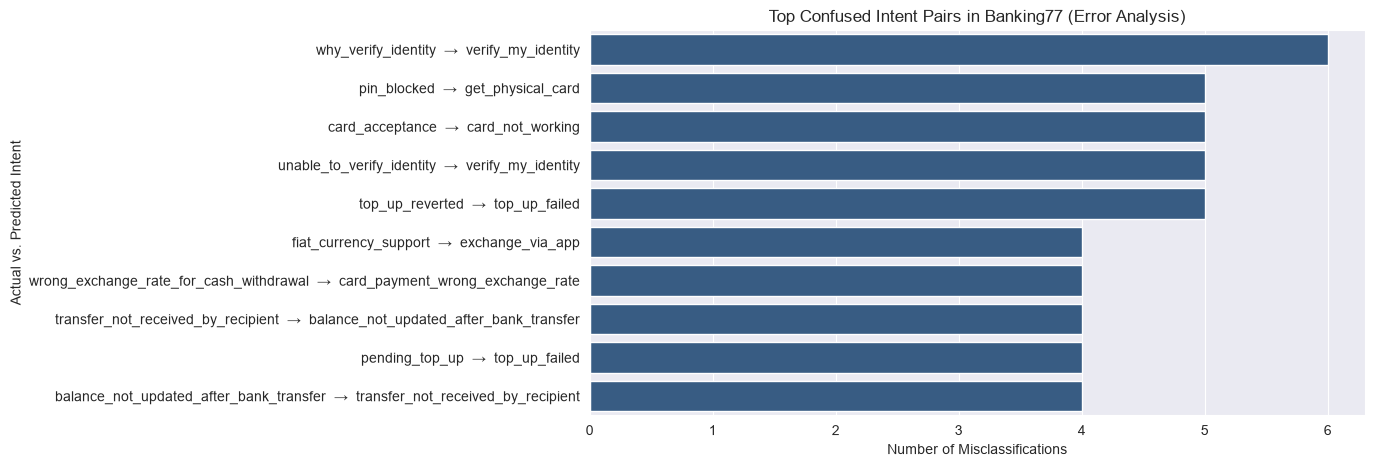

In [29]:
plt.figure(figsize=(10, 5))
pair_labels = confused_pairs["Actual Intent"] + "  →  " + confused_pairs["Predicted Intent"]
sns.barplot(x=confused_pairs["Error Count"], y=pair_labels, color="#2b5c8f")
plt.title("Top Confused Intent Pairs in Banking77 (Error Analysis)", fontsize=12)
plt.xlabel("Number of Misclassifications")
plt.ylabel("Actual vs. Predicted Intent")
plt.savefig("top_confused_intents.png", dpi=200, bbox_inches="tight")
plt.show()

### 3.5 Clean Prediction Cell (Track C Deliverable)
One presentable cell using Markdown to predict on new, unseen customer messages.

In [30]:
from IPython.display import display, Markdown

new_query = "My credit card was stolen while traveling in London, please freeze it right away!"

probs = model.predict_proba([new_query])[0]
top_idx = probs.argmax()
predicted_intent = categories[top_idx].replace("_", " ").title()
confidence = probs[top_idx] * 100

display(Markdown(f"""
### 🏦 **Customer Inquiry:**
> *"{new_query}"*

---
### 🎯 **Model Prediction:**
We predict this customer intent is **`{predicted_intent}`** with **{confidence:.1f}%** confidence.
"""))


### 🏦 **Customer Inquiry:**
> *"My credit card was stolen while traveling in London, please freeze it right away!"*

---
### 🎯 **Model Prediction:**
We predict this customer intent is **`Lost Or Stolen Card`** with **27.3%** confidence.
